In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("00 titanic.csv")

In [3]:
df.sample(10)

,Cabin,Ticket,number,Survived
332,C91,PC 17582,1,0
883,NaN,C.A./SOTON 34068,1,0
749,NaN,335097,1,0
571,C101,11769,6,1
408,NaN,312992,A,0
21,D56,248698,4,1
868,NaN,345777,A,0
268,C125,PC 17582,3,1
197,NaN,4579,6,0
78,NaN,248738,6,1


In [4]:
df.dtypes

Cabin       object
Ticket      object
number      object
Survived     int64
dtype: object

# Number column

Text(0.5, 1.0, 'Passengers travelling with')

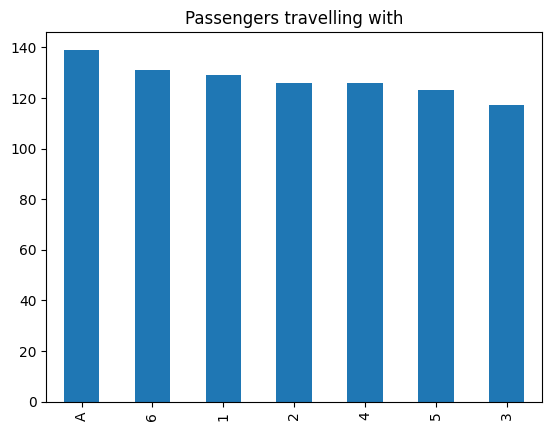

In [5]:
fig = df['number'].value_counts().plot.bar()
fig.set_title("Passengers travelling with")

# We can see how many passengers are traveling with how many companions.

In [6]:
# When we have such column where we have both numeric and categorical values(Not in single cell), use below method.
# Here, 'number' column has both, numeric and categorical values(Not in single cell).

# Extract numeric part.
df['number_numeric'] = pd.to_numeric(df['number'], errors = 'coerce', downcast = 'integer')

'''
'to_numeric()' will convert numeric string to integer and errors = 'coerce' means, if there is any categorical string, then it will
set NaN in that cell.
'''

"\n'to_numeric()' will convert numeric string to integer and errors = 'coerce' means, if there is any categorical string, then it will\nset NaN in that cell.\n"

In [7]:
df

,Cabin,Ticket,number,Survived,number_numeric
0,NaN,A/5 21171,5,0,5.0
1,C85,PC 17599,3,1,3.0
2,NaN,STON/O2. 3101282,6,1,6.0
3,C123,113803,3,1,3.0
4,NaN,373450,A,0,NaN
...,...,...,...,...,...
886,NaN,211536,3,0,3.0
887,B42,112053,3,1,3.0
888,NaN,W./C. 6607,1,0,1.0
889,C148,111369,2,1,2.0


In [8]:
# Extract categorical part.

df['number_categorical'] = np.where(df['number_numeric'].isnull(), df['number'], np.nan)

In [9]:
df.sample(10)

,Cabin,Ticket,number,Survived,number_numeric,number_categorical
3,C123,113803,3,1,3.0,NaN
636,NaN,STON/O 2. 3101292,A,0,NaN,A
440,NaN,F.C.C. 13529,4,1,4.0,NaN
827,NaN,S.C./PARIS 2079,5,1,5.0,NaN
508,NaN,C 4001,5,0,5.0,NaN
635,NaN,237668,A,1,NaN,A
518,NaN,226875,3,1,3.0,NaN
555,NaN,113807,A,0,NaN,A
349,NaN,315088,A,0,NaN,A
849,C92,17453,A,1,NaN,A


# Cabin column and Ticket column: These columns has both numerical and categorical values in single cell. So let's see how to deal with it.

In [10]:
df['Cabin'].str.extract('(\d+)')   # Dtype of tickek column is obj, so using .str

,0
0,NaN
1,85
2,NaN
3,123
4,NaN
...,...
886,NaN
887,42
888,NaN
889,148


In [11]:
# Extracting numbers from 'Cabin' column
df['Cabin_numeric'] = df['Cabin'].str.extract('(\d+)')

# Converting numbers to integer datatype.
df['Cabin_numeric'] = pd.to_numeric(df.Cabin_numeric, errors = 'coerce', downcast = 'integer')

In [12]:
df.sample(10)

,Cabin,Ticket,number,Survived,number_numeric,number_categorical,Cabin_numeric
191,NaN,28424,3,0,3.0,NaN,NaN
554,NaN,347085,3,1,3.0,NaN,NaN
632,B50,13214,5,1,5.0,NaN,50.0
355,NaN,345783,4,0,4.0,NaN,NaN
50,NaN,3101295,1,0,1.0,NaN,NaN
129,NaN,347061,A,0,NaN,A,NaN
430,C52,110564,A,1,NaN,A,52.0
439,NaN,C.A. 18723,1,0,1.0,NaN,NaN
459,NaN,371060,3,0,3.0,NaN,NaN
51,NaN,A/4. 39886,A,0,NaN,A,NaN


In [13]:
# Extracting first character(Which is a letter here) from 'Cabin' column.

df['Cabin'].str[0]

0      NaN
1        C
2      NaN
3        C
4      NaN
      ... 
886    NaN
887      B
888    NaN
889      C
890    NaN
Name: Cabin, Length: 891, dtype: object

In [14]:
df['Cabin_categorical'] = df['Cabin'].str[0]

In [15]:
df.sample(10)

,Cabin,Ticket,number,Survived,number_numeric,number_categorical,Cabin_numeric,Cabin_categorical
135,NaN,SC/PARIS 2133,1,0,1.0,NaN,NaN,NaN
867,A24,PC 17590,A,0,NaN,A,24.0,A
370,E50,11765,5,1,5.0,NaN,50.0,E
751,E121,392096,5,1,5.0,NaN,121.0,E
450,NaN,C.A. 34651,A,0,NaN,A,NaN,NaN
699,F G63,348121,A,0,NaN,A,63.0,F
120,NaN,S.O.C. 14879,A,0,NaN,A,NaN,NaN
343,NaN,244361,2,0,2.0,NaN,NaN,NaN
575,NaN,358585,1,0,1.0,NaN,NaN,NaN
220,NaN,SOTON/OQ 392089,5,1,5.0,NaN,NaN,NaN


# `Ticket` column.

In [16]:
df['Ticket'].apply(lambda s: s.split()[-1])

0        21171
1        17599
2      3101282
3       113803
4       373450
        ...   
886     211536
887     112053
888       6607
889     111369
890     370376
Name: Ticket, Length: 891, dtype: object

In [17]:
df.Ticket

0             A/5 21171
1              PC 17599
2      STON/O2. 3101282
3                113803
4                373450
             ...       
886              211536
887              112053
888          W./C. 6607
889              111369
890              370376
Name: Ticket, Length: 891, dtype: object

In [18]:
a = 'AB 1234'
a.split()[-1]

'1234'

In [19]:
# Extracting numbers from Ticket column
df['Ticket_numeric'] = df.Ticket.apply(lambda s: s.split()[-1])

# Converting extracted values to integer datatype.
df['Ticket_numeric'] = pd.to_numeric(df.Ticket_numeric, errors = 'coerce', downcast = 'integer')

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Cabin               204 non-null    object 
 1   Ticket              891 non-null    object 
 2   number              891 non-null    object 
 3   Survived            891 non-null    int64  
 4   number_numeric      752 non-null    float64
 5   number_categorical  139 non-null    object 
 6   Cabin_numeric       200 non-null    float64
 7   Cabin_categorical   204 non-null    object 
 8   Ticket_numeric      887 non-null    float64
dtypes: float64(3), int64(1), object(5)
memory usage: 62.8+ KB


In [21]:
# extract the last bit of ticket which is a number
df['Ticket_numeric'] = df['Ticket'].apply(lambda s: s.split() [-1])

# Converting the extracted values to integer datatype.
df['Ticket_numeric'] = pd.to_numeric(df.Ticket_numeric, errors = 'coerce', downcast = 'integer')

In [22]:
# extract the first part of ticket which is a category
df['Ticket_category'] = df['Ticket'].apply(lambda s: s.split()[0])

# Ticket column has some values which is only numeric.
# So, if first part is digit then convert it to Nan else keep it as it is (i.e categorical).
df.Ticket_category = np.where(df.Ticket_category.str.isdigit(), np.nan, df.Ticket_category)

In [23]:
df.head(25)

,Cabin,Ticket,number,Survived,number_numeric,number_categorical,Cabin_numeric,Cabin_categorical,Ticket_numeric,Ticket_category
0,NaN,A/5 21171,5,0,5.0,NaN,NaN,NaN,21171.0,A/5
1,C85,PC 17599,3,1,3.0,NaN,85.0,C,17599.0,PC
2,NaN,STON/O2. 3101282,6,1,6.0,NaN,NaN,NaN,3101282.0,STON/O2.
3,C123,113803,3,1,3.0,NaN,123.0,C,113803.0,NaN
4,NaN,373450,A,0,NaN,A,NaN,NaN,373450.0,NaN
5,NaN,330877,2,0,2.0,NaN,NaN,NaN,330877.0,NaN
6,E46,17463,2,0,2.0,NaN,46.0,E,17463.0,NaN
7,NaN,349909,5,0,5.0,NaN,NaN,NaN,349909.0,NaN
8,NaN,347742,1,1,1.0,NaN,NaN,NaN,347742.0,NaN
9,NaN,237736,A,1,NaN,A,NaN,NaN,237736.0,NaN
